In [73]:
TrainData_name = 'Mawqif_AllTargets_Train.csv'
TestData_name = 'Mawqif_AllTargets_Test.csv'

Enable_TargetSpecefic = 'No' #'Yes'
selectedTarget = 'All'
#selectedTarget = 'Covid Vaccine'
#selectedTarget = 'Digital Transformation'
#selectedTarget = 'Women empowerment'

Weight = "UW" 

Ex_name = Weight + '_STL_'+'logging_'+'Sar-Sent_'+selectedTarget

#"UBC-NLP/MARBERT
#"aubmindlab/bert-base-arabertv02"
#"CAMeL-Lab/bert-base-arabic-camelbert-da"
model_name = "aubmindlab/bert-base-arabertv02-twitter"

# Environment Settings

In [74]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "1"

In [75]:
import torch

# If there's a GPU available...
if torch.cuda.is_available():    

    # Tell PyTorch to use the GPU.    
    device = torch.device("cuda")

    print('There are %d GPU(s) available.' % torch.cuda.device_count())

    print('We will use the GPU:', torch.cuda.get_device_name(0))
    !nvidia-smi

# If not...
else:
    print('No GPU available, using the CPU instead.')
    device = torch.device("cpu")

There are 1 GPU(s) available.
We will use the GPU: NVIDIA RTX A6000
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
Wed Apr 26 11:24:33 2023       
+-----------------------------------------------------------------------------+
| NVIDIA-SMI 525.85.05    Driver Version: 525.85.05    CUDA Version: 12.0     |
|-------------------------------+----------------------+----------------------+
| GPU  Name        Persistence-M| Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp  Perf  Pwr:Usage/Cap|         Memory-Usage | GPU-Util  Compute M. |
|                               |                      |               MIG M. |
|===============================+======================+======================|
|   0  NVIDIA RT

In [76]:
!pip install transformers datasets --quiet
!pip install farasapy==0.0.14 --quiet
!pip install PyArabic==0.6.14 --quiet 

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


In [77]:
# Import Basics
import pandas as pd
import numpy as np
import random
from tqdm.auto import tqdm
import pickle
import re
import os
import sys

from dataclasses import dataclass, field
from typing import Optional
import datasets
from datasets import ClassLabel, load_dataset, Dataset, DatasetDict
import string
from typing import Dict ,List


In [78]:
# Import for models
import transformers
from transformers import AutoTokenizer, AutoModel

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

import torch.nn as nn


In [79]:
# Visualisation
import seaborn as sns
from pylab import rcParams
import matplotlib.pyplot as plt
from matplotlib import rc

%matplotlib inline
%config InlineBackend.figure_format='retina'
sns.set(style='whitegrid', palette='muted', font_scale=1.2)
rcParams['figure.figsize'] = 16, 10
tqdm.pandas()

# Prepare data

## Load data to colab drive

In [80]:
df = pd.read_csv(TrainData_name)
test_df = pd.read_csv(TestData_name)

## Label mapping

In [81]:
# Stance
mapping_stance = {'None': 2, 'Favor': 1, 'Against': 0}

df['stance'] = df['stance'].apply(lambda x: mapping_stance[x])
test_df['stance'] = test_df['stance'].apply(lambda x: mapping_stance[x])

# Sentiment
mapping_sent = {'Neutral': 2, 'Positive': 1, 'Negative': 0}

df['sentiment'] = df['sentiment'].apply(lambda x: mapping_sent[x])
test_df['sentiment'] = test_df['sentiment'].apply(lambda x: mapping_sent[x])

# Sarcasm
mapping_sarcasm = {"Yes": 1, "No": 0}

df['sarcasm'] = df['sarcasm'].apply(lambda x: mapping_sarcasm[x])
test_df['sarcasm'] = test_df['sarcasm'].apply(lambda x: mapping_sarcasm[x])

In [82]:
# Mapping targets

mapping_targets = {'Women empowerment': 'تمكين المرأة', 'Digital Transformation': 'التحول الرقمي', 'Covid Vaccine': 'لقاح كورونا'}

df['target'] = df['target'].apply(lambda x: mapping_targets[x])
test_df['target'] = test_df['target'].apply(lambda x: mapping_targets[x])


## Data Analysis

In [83]:
print(df.shape)
print(test_df.shape)

(3502, 14)
(619, 14)


In [84]:
test_df.head()

,ID,text,target,stance,stance:confidence,against_reason,favor_reason,none_reason,sarcasm,sarcasm:confidence,sentiment,sentiment:confidence,datetime,Date
0,2,الوضع صار بالسعوديه يفشل لا عاد فيه شركات صاحي...,تمكين المرأة,0,1.0000,A_Explicit,NaN,NaN,0,1.0000,0,1.0000,2022-01-26 21:46:08+00:00,26/01/2022
1,5,الفساد الإداري انهك البلاد ومازلنا نعتمد عل...,التحول الرقمي,1,1.0000,NaN,F_Explicit,NaN,0,1.0000,2,0.4227,2022-03-22 08:30:35+00:00,22/03/2022
2,14,-البي بي سي ١٠ دول اوروبية توقف تطعيم اوكسفورد...,لقاح كورونا,0,0.8226,A_Explicit,NaN,NaN,0,0.8577,0,1.0000,2021-03-12 05:33:54+00:00,12/03/2021
3,16,منصة مدرستي بتسرع عملية التحول للتعليم الالكتر...,التحول الرقمي,1,0.7433,NaN,F_Explicit,NaN,0,1.0000,1,0.6393,2020-08-27 09:21:25+00:00,27/08/2020
4,17,انا مع تمكين المرأة اصلا URL,تمكين المرأة,1,1.0000,NaN,F_Explicit,NaN,0,1.0000,1,0.8191,2022-05-16 23:47:42+00:00,16/05/2022


In [85]:
df['stance'].value_counts()

1    2148
0    1021
2     333
Name: stance, dtype: int64

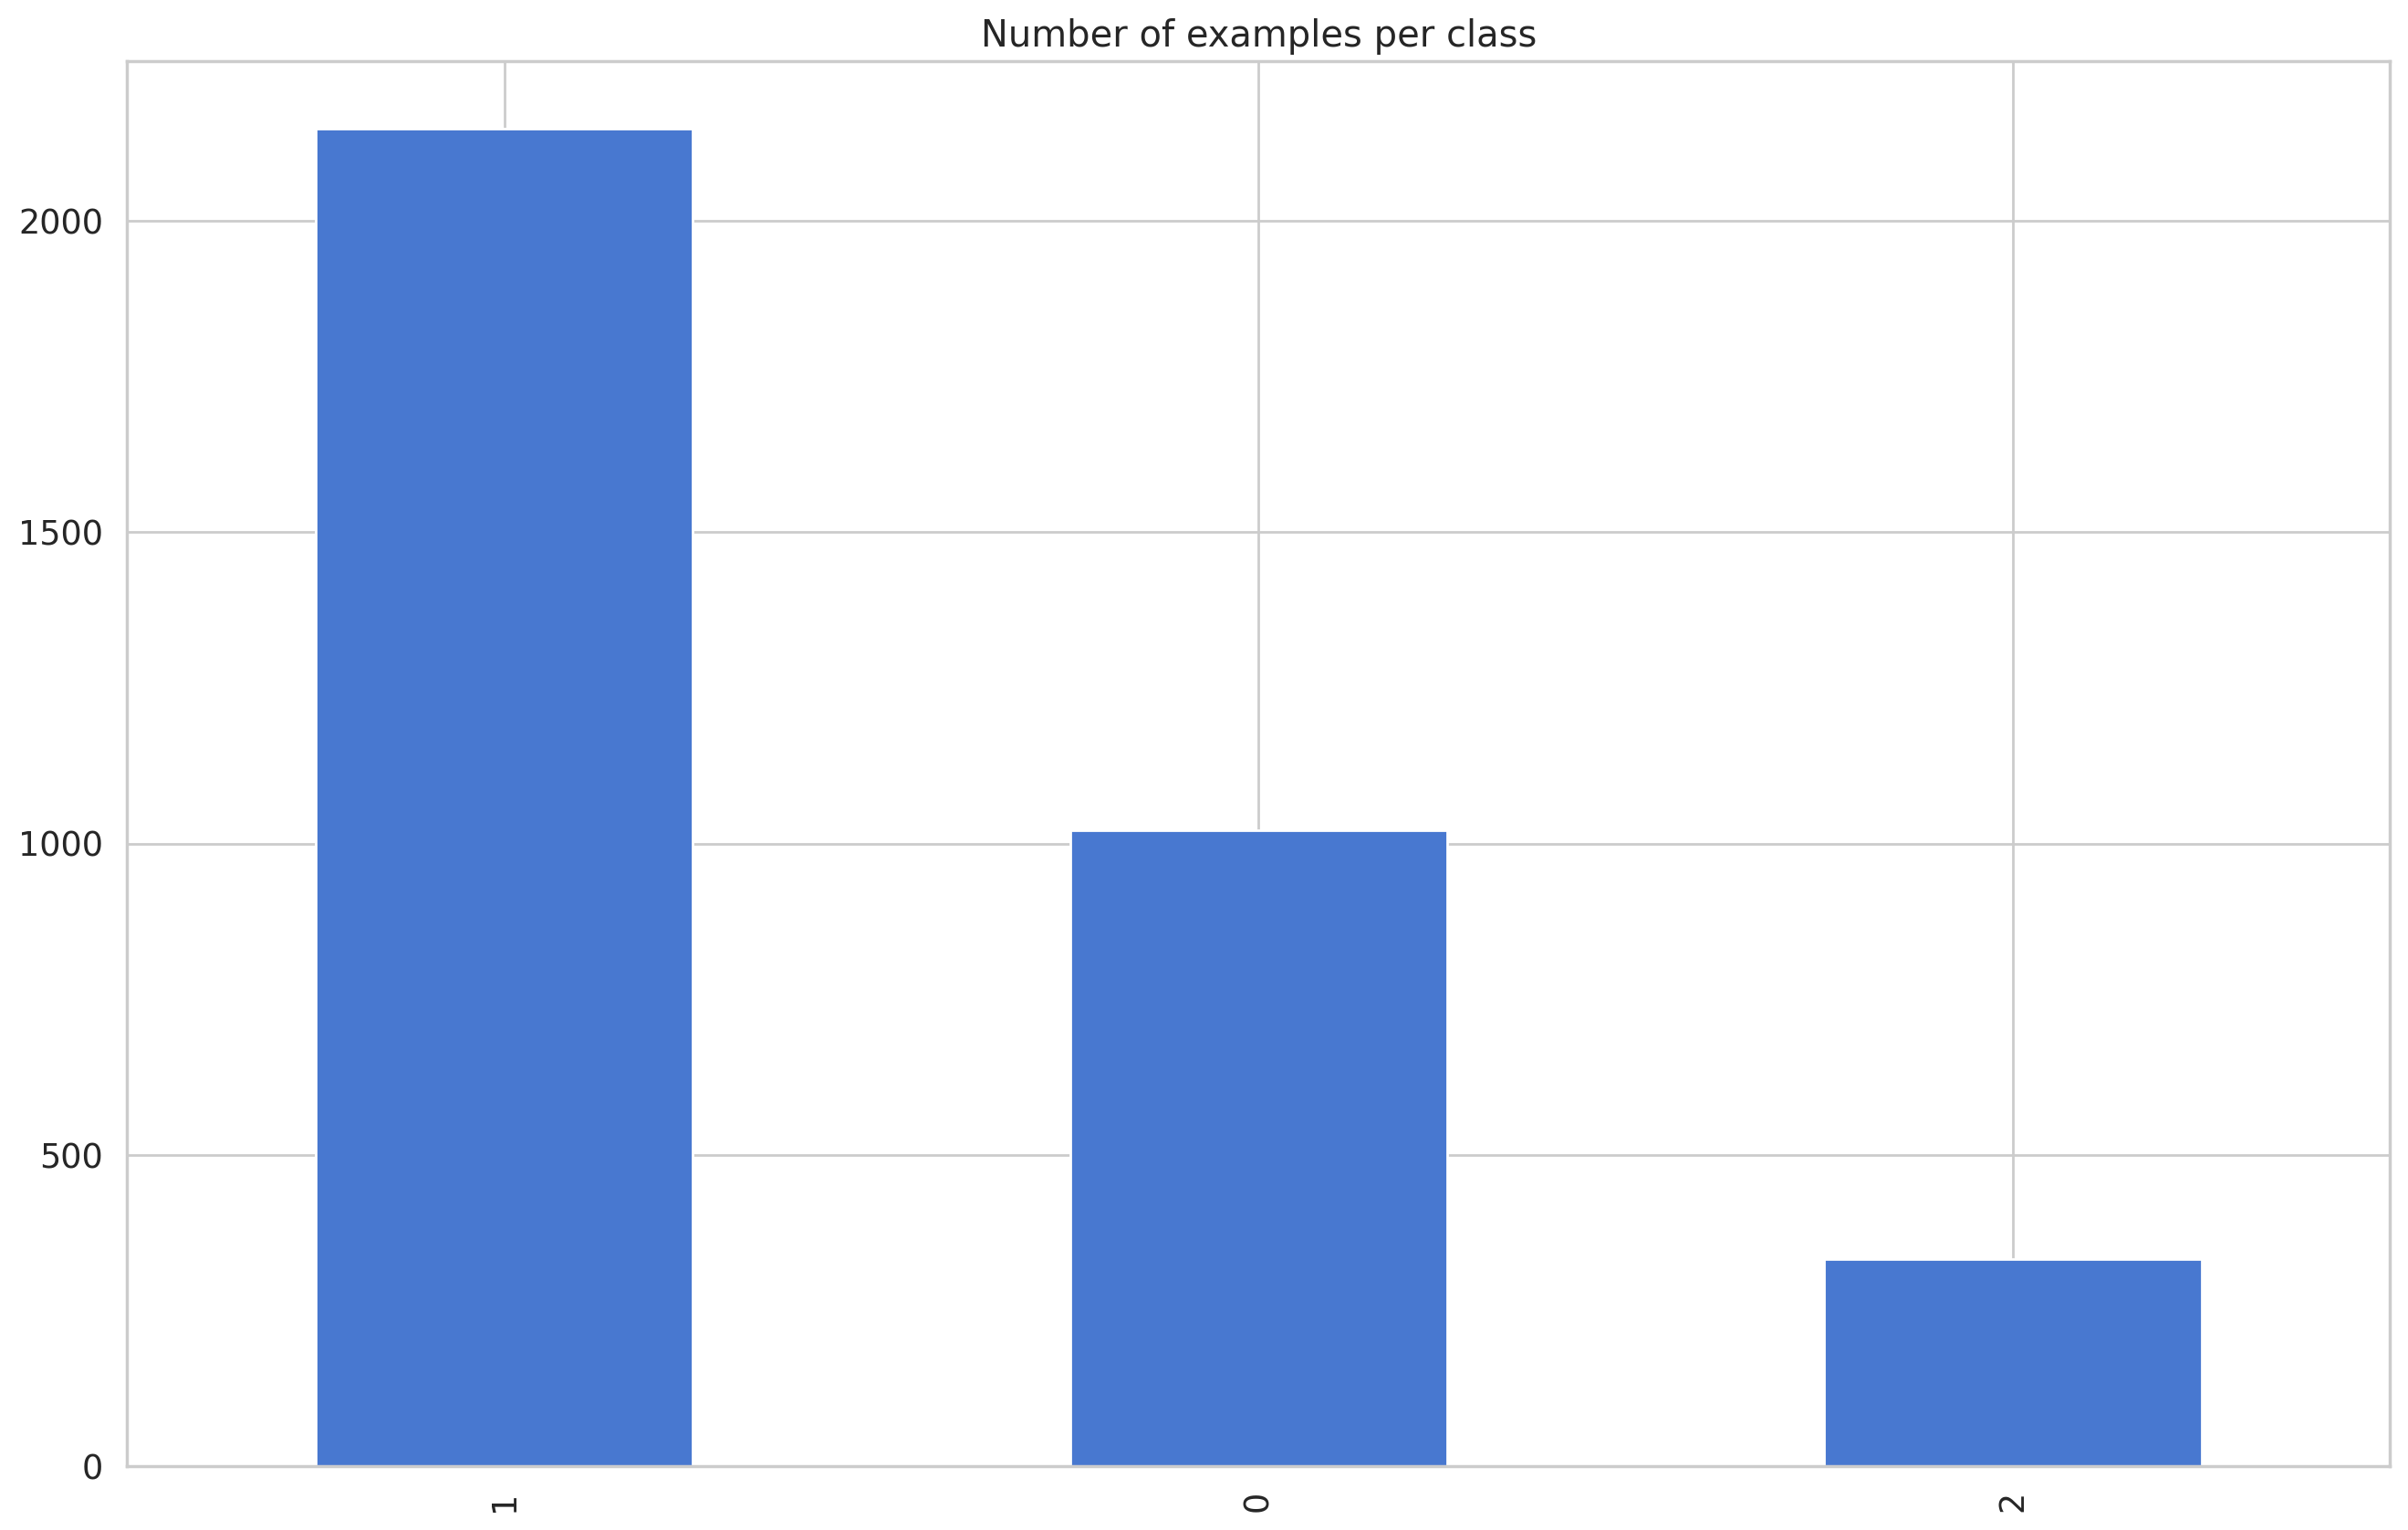

In [86]:
df['stance'].value_counts().sort_values(ascending=False).plot(kind="bar")
plt.title("Number of examples per class");

## Define specefic target

In [87]:
#Include only rows from specefic target
if Enable_TargetSpecefic == 'Yes':
  df= df[df['target'] == selectedTarget]
  test_df= test_df[test_df['target'] == selectedTarget]

print(df.shape)
print(test_df.shape)

(3502, 14)
(619, 14)


## Load data into Huggingface 

In [88]:
# load the dataset from pandas dataframe to Huggingface Dataset

tds = Dataset.from_pandas(df)
vds = Dataset.from_pandas(test_df)

loaded_datasets = DatasetDict()

loaded_datasets['train'] = tds
loaded_datasets['validation'] = vds

In [89]:
loaded_datasets

DatasetDict({
    train: Dataset({
        features: ['ID', 'text', 'target', 'stance', 'stance:confidence', 'against_reason', 'favor_reason', 'none_reason', 'sarcasm', 'sarcasm:confidence', 'sentiment', 'sentiment:confidence', 'datetime', 'Date'],
        num_rows: 3502
    })
    validation: Dataset({
        features: ['ID', 'text', 'target', 'stance', 'stance:confidence', 'against_reason', 'favor_reason', 'none_reason', 'sarcasm', 'sarcasm:confidence', 'sentiment', 'sentiment:confidence', 'datetime', 'Date'],
        num_rows: 619
    })
})

In [90]:
# Remove the extra column '__index_level_0__' when we convert from pandas to Huggingface
if '__index_level_0__' in loaded_datasets['train'].features:
    loaded_datasets = loaded_datasets.remove_columns(['__index_level_0__'])

## Preprocessing the tweets

### Regex preprocessing 

In [91]:
## Remove hashtags, URL, MENTION

def remove_hash_URL_MEN(text):
    #text = re.sub(r'#(\w+)','',text)
    text = re.sub(r'#',' ',text) #remove #
    text = re.sub(r'_',' ',text) #remove _
    text = re.sub(r'URL','',text)
    text = re.sub(r'MENTION','',text)
    return text

##  Remove punctuations

arabic_punctuations = '''`÷×؛<>()*&^%][ـ،/:"؟.,'{}~¦+|!”…“–ـ'''
english_punctuations = string.punctuation
punctuations_list = arabic_punctuations + english_punctuations

def remove_punctuations(text):
    translator = str.maketrans('', '', punctuations_list)
    return text.translate(translator)

##  Normalize_arabic

def normalize_arabic(text):
    text = re.sub("[إآ]", "ا", text)
    #text = re.sub("ى", "ي", text)
    #text = re.sub("ة", "ه", text)
    text = re.sub("گ", "ك", text)
    return text


## Remove_repeating_char

def remove_repeating_char(text):
    return re.sub(r'(.)\1+', r'\1', text)


# one4all preprocess

def processPost(tweet): 
    tweet['text']=remove_hash_URL_MEN(str(tweet['text']))

    #Replace @username with empty string
    tweet['text'] = re.sub('@[^\s]+', ' ', str(tweet['text']))
    
    #Convert www.* or https?://* to " "
    tweet['text'] = re.sub('((www\.[^\s]+)|(https?://[^\s]+))',' ',str(tweet['text']))
    
    #Replace #word with word
    #tweet['text'] = re.sub(r'#([^\s]+)', r'\1', str(tweet['text']))

    # remove punctuations
    #tweet['text']= remove_punctuations(str(tweet['text']))
    
    # normalize the tweet
    tweet['text']= normalize_arabic(str(tweet['text']))
    
    # remove repeated letters
    #tweet['text']=remove_repeating_char(str(tweet['text']))

    return tweet

In [92]:
# Regex preprocessing before tokenizing
loaded_datasets["train"] = loaded_datasets["train"].map(processPost)
loaded_datasets["validation"] = loaded_datasets["validation"].map(processPost)

Map:   0%|          | 0/3502 [00:00<?, ? examples/s]

Map:   0%|          | 0/619 [00:00<?, ? examples/s]

In [93]:
# Sanity check on the dataset after Regex processing
list(loaded_datasets["validation"]['text'][0:20])

##Q: some emojis is not included in the vocab

['الوضع صار بالسعوديه يفشل لا عاد فيه شركات صاحيه ولا مشاهير صاحين.  الوضع الحالي اقبح صور تسليع المرأه تحت مسمى تمكين المرأه!   مقاطعة شاهي خدير',
 '   الفساد الاداري انهك البلاد ومازلنا نعتمد على السندات اليدويه لتحصيل الايرادات لابد من التحول الالكتروني وبذالك نظمن جميع الايرادات',
 '-البي بي سي ١٠ دول اوروبية توقف تطعيم اوكسفورد..  -اطباء الكويت التطعيم بريء وامن..!!  تسويق وترقيع على حساب البشر غير معقول!!   لا للحظر  كورونا  التطعيم ',
 'منصة مدرستي بتسرع عملية التحول للتعليم الالكتروني. الان تقريبا جميع الطلاب معهم اجهزة اتمنى بعد انتهاء كورونا يسمحون لهم يجيبونها للمدرسة.',
 'انا مع تمكين المرأة اصلا ',
 '«بنك مصر» الأفضل في مجال التحول الرقمي وخدمات الصراف الالي والدفع الالكتروني ',
 ' نقل الاموال مكلفة وخطرة وطبع النقود بعد مكلف عشان كذا التحول للدفع الالكتروني. الكاش يضيع او ينسرق او يتلف',
 'من خلال تقديمي لدورات وورش عمل  التجارة الالكترونية  التسويق الألكتروني  التحول الرقمي هناك تنافس محموم بين  قوقل و  فيسبوك للاستحواذ على سوق الاعمال والأنشطة التجارية والتسويق مع وجود 

### AraBERT preprocessing


In [94]:
!git clone https://github.com/aub-mind/arabert/

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
fatal: destination path 'arabert' already exists and is not an empty directory.


In [95]:
!pip install emoji==1.6.1

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


In [96]:
from arabert.preprocess import ArabertPreprocessor

#https://github.com/aub-mind/arabert/blob/master/preprocess.py
# Default values of parameters:
#ArabertPreprocessor(model_name: str, remove_html_markup: bool=True, replace_urls_emails_mentions: bool=True, strip_tashkeel: bool=True, 
#                    strip_tatweel: bool=True, insert_white_spaces: bool=True, remove_non_digit_repetition: bool=True, keep_emojis: bool=None,
#                    replace_slash_with_dash: bool=None, map_hindi_numbers_to_arabic: bool=None, apply_farasa_segmentation: bool=None)

arabert_prep = ArabertPreprocessor(model_name=model_name) #keep_emojis will be automatically set to True in AraBERT-twitter.


In [97]:
sample_tweet = test_df.iloc[10]
sample_tweet.text

'من أسباب "تمكين" المرأة المزعوم: ١-أن تستفيد الدولة الرأسمالية من الضرائب والأجور التي ستدفعها المرأة بجانب الرجل  أي ستتضاعف الضرائب والعائدات لخزينة الدولة من المواطن ٢-إلغاء الأسرة وترسية قيم الفردية والأنانية وأبوية النظام (النظام هو الأب والأسرة) بلغوا من تتشدق بـ "أنا حرة"'

In [98]:
sample_text = arabert_prep.preprocess(sample_tweet.text)
sample_text

'من أسباب " تمكين " المرأة المزعوم : 1 - أن تستفيد الدولة الرأسمالية من الضرائب والأجور التي ستدفعها المرأة بجانب الرجل أي ستتضاعف الضرائب والعائدات لخزينة الدولة من المواطن 2 - إلغاء الأسرة وترسية قيم الفردية والأنانية وأبوية النظام ( النظام هو الأب والأسرة ) بلغوا من تتشدق ب " أنا حرة "'

In [99]:
# Convert dataset to dataframe for easy manipulation to apply arabert_prep.preprocess
df_pandas_train = pd.DataFrame(loaded_datasets['train'])
df_pandas_valid = pd.DataFrame(loaded_datasets['validation'])

# Apply arabert_prep.preprocess
df_pandas_train['text'] = df_pandas_train['text'].apply(lambda x: arabert_prep.preprocess(x))
df_pandas_valid['text'] = df_pandas_valid['text'].apply(lambda x: arabert_prep.preprocess(x))

# Recover to HF dataset
loaded_datasets['train']=loaded_datasets['train'].from_pandas(df_pandas_train)
loaded_datasets['validation']=loaded_datasets['validation'].from_pandas(df_pandas_valid)

In [100]:
# Sanity check on the dataset after arabert processing
list(loaded_datasets['validation']['text'][0:20])

['الوضع صار بالسعوديه يفشل لا عاد فيه شركات صاحيه ولا مشاهير صاحين . الوضع الحالي اقبح صور تسليع المرأه تحت مسمى تمكين المرأه ! مقاطعة شاهي خدير',
 'الفساد الاداري انهك البلاد ومازلنا نعتمد على السندات اليدويه لتحصيل الايرادات لابد من التحول الالكتروني وبذالك نظمن جميع الايرادات',
 '- البي بي سي 10 دول اوروبية توقف تطعيم اوكسفورد . . - اطباء الكويت التطعيم بريء وامن . . ! ! تسويق وترقيع على حساب البشر غير معقول ! ! لا للحظر كورونا التطعيم',
 'منصة مدرستي بتسرع عملية التحول للتعليم الالكتروني . الان تقريبا جميع الطلاب معهم اجهزة اتمنى بعد انتهاء كورونا يسمحون لهم يجيبونها للمدرسة .',
 'انا مع تمكين المرأة اصلا',
 '« بنك مصر » الأفضل في مجال التحول الرقمي وخدمات الصراف الالي والدفع الالكتروني',
 'نقل الاموال مكلفة وخطرة وطبع النقود بعد مكلف عشان كذا التحول للدفع الالكتروني . الكاش يضيع او ينسرق او يتلف',
 'من خلال تقديمي لدورات وورش عمل التجارة الالكترونية التسويق الألكتروني التحول الرقمي هناك تنافس محموم بين قوقل و فيسبوك للاستحواذ على سوق الاعمال والأنشطة التجارية والتسويق مع وجود مناف

In [101]:
loaded_datasets

DatasetDict({
    train: Dataset({
        features: ['ID', 'text', 'target', 'stance', 'stance:confidence', 'against_reason', 'favor_reason', 'none_reason', 'sarcasm', 'sarcasm:confidence', 'sentiment', 'sentiment:confidence', 'datetime', 'Date'],
        num_rows: 3502
    })
    validation: Dataset({
        features: ['ID', 'text', 'target', 'stance', 'stance:confidence', 'against_reason', 'favor_reason', 'none_reason', 'sarcasm', 'sarcasm:confidence', 'sentiment', 'sentiment:confidence', 'datetime', 'Date'],
        num_rows: 619
    })
})

# Building The Multi-Task Dataset

1. Define the tokenizer
2. Build and tokenize the stance_dataset
3. Build and tokenize the sentiment_dataset
4. Build and tokenize the sarcasm_dataset
5. Merge all datasets

In [102]:
## Parameters
max_length= 128 
seednum= 123

In [103]:
## Define the tokenizer        
tokenizer = AutoTokenizer.from_pretrained(model_name) #,add_prefix_space=True)

loading file vocab.txt from cache at /home/nora_alturayeif/.cache/huggingface/hub/models--aubmindlab--bert-base-arabertv02-twitter/snapshots/0decc2e761667f0aea7aa94546ada5a32a6e5bb8/vocab.txt
loading file tokenizer.json from cache at /home/nora_alturayeif/.cache/huggingface/hub/models--aubmindlab--bert-base-arabertv02-twitter/snapshots/0decc2e761667f0aea7aa94546ada5a32a6e5bb8/tokenizer.json
loading file added_tokens.json from cache at None
loading file special_tokens_map.json from cache at /home/nora_alturayeif/.cache/huggingface/hub/models--aubmindlab--bert-base-arabertv02-twitter/snapshots/0decc2e761667f0aea7aa94546ada5a32a6e5bb8/special_tokens_map.json
loading file tokenizer_config.json from cache at /home/nora_alturayeif/.cache/huggingface/hub/models--aubmindlab--bert-base-arabertv02-twitter/snapshots/0decc2e761667f0aea7aa94546ada5a32a6e5bb8/tokenizer_config.json


In [104]:
# A class for the task, inherit from dataclass where we specifie id, name ,type,num_labels
@dataclass
class Task:
    id: int
    name: str
    type: str
    num_labels: int

### Stance dataset

In [105]:
def load_stance_dataset():
    
    task_name = 'stance'
    num_labels = 3  ### {'None': 2, 'Favor': 1, 'Against': 0}
    task_id=1 # id of the task

    def tokenize_text(examples):

        result = tokenizer(examples['text'], examples['target'],
              padding='max_length',max_length=max_length, truncation=True,
        )
        result["task_ids"] = [task_id] * len(examples["label"])

        return result

    raw_datasets = loaded_datasets

    ## We need to rename the column to merge all the datasets later
    raw_datasets = raw_datasets.rename_column('stance', 'label') # rename column 


    # removing the none class
    # change: num_labels =2 
    #############################################
    '''
    df_pandas_train = pd.DataFrame(raw_datasets['train'])# convert dataset to dataframe for easy manipulation
    df_pandas_valid = pd.DataFrame(raw_datasets['validation'])

    df_pandas_train=df_pandas_train[df_pandas_train['label']!=2]# remove third class (None,label=2)
    df_pandas_valid=df_pandas_valid[df_pandas_valid['label']!=2]
    
    raw_datasets['train']=raw_datasets['train'].from_pandas(df_pandas_train)# recover to dataset
    raw_datasets['validation']=raw_datasets['validation'].from_pandas(df_pandas_valid)

    raw_datasets = raw_datasets.remove_columns(['__index_level_0__'])# this index is added by pandas when convertint to dataset (need to be removed)
    '''
    #############################################

    # PreProcessing
    #raw_datasets["train"] = raw_datasets["train"].map(processPost)# preprocessing before tokenizing

    # Tokonizing , and remove columns
    col_to_remove=['ID','text','target','stance:confidence','against_reason','favor_reason','none_reason','sarcasm','sarcasm:confidence','sentiment','sentiment:confidence','datetime','Date']
    
    train_dataset = raw_datasets["train"].map(tokenize_text,batched=True,load_from_cache_file=True,remove_columns=col_to_remove)
    validation_dataset = raw_datasets["validation"].map(tokenize_text,batched=True,load_from_cache_file=True,remove_columns=col_to_remove)

    # Add task field
    task_info = Task(id=task_id, name=task_name, num_labels=num_labels, type="seq_classification" )
    
    return train_dataset,validation_dataset,task_info


In [106]:
load_stance_dataset()

Map:   0%|          | 0/3502 [00:00<?, ? examples/s]

Map:   0%|          | 0/619 [00:00<?, ? examples/s]

(Dataset({
     features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
     num_rows: 3502
 }),
 Dataset({
     features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
     num_rows: 619
 }),
 Task(id=1, name='stance', type='seq_classification', num_labels=3))

### Sentiment dataset

In [107]:
def load_sentiment_dataset():
    
    task_name = 'sentiment'
    num_labels =3 # {'Neutral': 2, 'Positive': 1, 'Negative': 0}
    task_id=2
  
    def tokenize_text(examples):

        result = tokenizer(examples['text'],
              padding='max_length',max_length=max_length, truncation=True,
        )
        result["task_ids"] = [task_id] * len(examples["label"])

        return result

    raw_datasets = loaded_datasets
    raw_datasets = raw_datasets .rename_column('sentiment', 'label')# rename column

    # PreProcessing
    #raw_datasets["train"] = raw_datasets["train"].map(processPost)# preprocessing before tokenizing

    # Tokonizing , and remove columns
    col_to_remove=['ID','text','target','stance','stance:confidence','against_reason','favor_reason','none_reason','sarcasm','sarcasm:confidence','sentiment:confidence','datetime','Date']
    
    train_dataset = raw_datasets["train"].map(tokenize_text,batched=True,load_from_cache_file=True,remove_columns=col_to_remove)
    validation_dataset = raw_datasets["validation"].map(tokenize_text,batched=True,load_from_cache_file=True,remove_columns=col_to_remove)

    # Add task field
    task_info = Task(id=task_id, name=task_name, num_labels=num_labels, type="seq_classification" )

    return train_dataset,validation_dataset,task_info


In [108]:
load_sentiment_dataset()

Map:   0%|          | 0/3502 [00:00<?, ? examples/s]

Map:   0%|          | 0/619 [00:00<?, ? examples/s]

(Dataset({
     features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
     num_rows: 3502
 }),
 Dataset({
     features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
     num_rows: 619
 }),
 Task(id=2, name='sentiment', type='seq_classification', num_labels=3))

### Sarcasm dataset

In [109]:
def load_sarcasm_dataset():
    
    task_name = 'sarcasm'
    num_labels =2 # {"Yes": 1, "No": 0}
    task_id=3

    def tokenize_text(examples):

        result = tokenizer(examples['text'],
              padding='max_length',max_length=max_length, truncation=True,
        )
        result["task_ids"] = [task_id] * len(examples["label"])

        return result


    raw_datasets = loaded_datasets
    raw_datasets = raw_datasets .rename_column('sarcasm', 'label')# rename column

    # PreProcessing
    #raw_datasets["train"] = raw_datasets["train"].map(processPost)# preprocessing before tokenizing

    # Tokonizing , and remove columns
    col_to_remove=['ID','text','target','stance','stance:confidence','against_reason','favor_reason','none_reason','sarcasm:confidence','sentiment','sentiment:confidence','datetime','Date']
    
    train_dataset = raw_datasets["train"].map(tokenize_text,batched=True,load_from_cache_file=True,remove_columns=col_to_remove)
    validation_dataset = raw_datasets["validation"].map(tokenize_text,batched=True,load_from_cache_file=True,remove_columns=col_to_remove)

    # Add task field
    task_info = Task(id=task_id, name=task_name, num_labels=num_labels, type="seq_classification" )
    
    return train_dataset,validation_dataset,task_info

In [110]:
load_sarcasm_dataset()

Map:   0%|          | 0/3502 [00:00<?, ? examples/s]

Map:   0%|          | 0/619 [00:00<?, ? examples/s]

(Dataset({
     features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
     num_rows: 3502
 }),
 Dataset({
     features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
     num_rows: 619
 }),
 Task(id=3, name='sarcasm', type='seq_classification', num_labels=2))

### Merging the 3 datasets

In [111]:
#def load_datasets(tokenizer, pad_to_max_length,max_seq_length,label_all_tokens ,preprocessing_num_workers,overwrite_cache):

def load_datasets():
    # load three datasets and merge it to have only one dataset 
    (
        seq_classification_train_dataset1,
        seq_classification_validation_dataset1,
        seq_classification_task1,
    ) = load_stance_dataset()

    (
        seq_classification_train_dataset2,
        seq_classification_validation_dataset2,
        seq_classification_task2,
    ) = load_sentiment_dataset()

    (
        seq_classification_train_dataset3,
        seq_classification_validation_dataset3,
        seq_classification_task3,
    ) = load_sarcasm_dataset()
 

    # Merge train datasets
    train_dataset_df = seq_classification_train_dataset1.to_pandas().append(
        seq_classification_train_dataset2.to_pandas().append(
            seq_classification_train_dataset3.to_pandas()
            )
    )

    train_dataset = datasets.Dataset.from_pandas(train_dataset_df)
    train_dataset=train_dataset.shuffle(seed=seednum)

    # Append validation datasets
    validation_dataset = [
        seq_classification_validation_dataset1,
        seq_classification_validation_dataset2,
        seq_classification_validation_dataset3
    ]

    dataset = datasets.DatasetDict(
        {"train": train_dataset, "validation": validation_dataset}
    )
    
    tasks = [seq_classification_task1, seq_classification_task2, seq_classification_task3]

    return tasks, dataset


# CL Model

**Steps of CL model:**
1. Create attention heads with different layers
2. Define the encoder
3. Build CL model
--------

There is 3 tasks we can face in our CL implementation, so in evrey task an action is taken for:

1. **Sarcasm task:**
* when the batch had a sarcasm task it's mean we are in the first level.
* the 1, 2 and 3 level need  to be updated 
* the NN of sarcasm will feed the NN of sentiment and the NN sentiment will feed the NN stance
* the information (sarcasm) need to be passed throw 3 layers (hidden layer sarcasm, hidden layer sent, hidden layer stance )

2. **Sentiment task:**
* when the batch had a sentiment task it's mean we are in the second level.
* the 2 and 3 level need  to be updated 
* the NN sentiment will feed the NN stance
* the information (sentiment) need to be passed throw 2 layers ( hidden layer sentiment, hidden layer stance )

3. **Stance task:**
* when the batch had a stance task it's mean we are in the third level.
* the 3rd level need to be updated 
* the NN stance will be updated
* the information (stance) need to be passed throw it self ( hidden layer stance )
------
**NB:** in every level (task) we added 1 hidden layer (1 hidden layer for each task)

### Loss

Uncertainty


In [112]:
 ### UW ###
def generate_parameter():
    
    log_var2 = nn.Parameter(torch.zeros(1,), requires_grad=True) #homoscedastic
    
    return log_var2 

In [113]:
def loss_task(loss_fct, logits, num_labels, labels, log_var2):
    
    diff = loss_fct(
        logits.view(-1, num_labels), labels.view(-1)
            )
    
    factor = torch.exp(-log_var2) # we will get 1/var2
    
    var2 = torch.exp(log_var2)
    var = torch.sqrt(var2)
    
    loss = torch.sum(factor * diff + torch.log(var), -1)
    
    return loss

### Sarcasm Head

In [114]:
class SequenceClassificationHeadSarcasm(nn.Module):

    def __init__(self, hidden_size, num_labels,
                 hidden_layer_sarc,sarc_classifier,
                 hidden_layer_sent,sent_classifier,
                 hidden_layer_stan,stan_classifier,
                 activation,get_activation,
                 dropout_p=0.1):
        super().__init__()

        self.num_labels = num_labels
        #self.dropout = nn.Dropout(dropout_p)
        ###
        self.classifier = sarc_classifier
        self.activation = activation
        self.get_activation = get_activation
        ###
        ### UW ###
        self.sigmas = generate_parameter()

        ## 3 layers need to be updated (sentiment hidden_layer, sarcasm hidden_layer, stance hidden_layer)
        self.hidden_layer_sarc=hidden_layer_sarc
        self.hidden_layer_sent=hidden_layer_sent
        self.hidden_layer_stan=hidden_layer_stan
        ##

        ### this layer will pass the input to output with no modification so we use it to keep track of the losses:
        self.sarc_id = nn.Identity()


    def forward(self,pooled_output, labels=None, **kwargs):

        #pooled_output = self.dropout(pooled_output)
        ## first case 3 level are changed
        output_level1=self.hidden_layer_sarc(pooled_output)# pooled_output of the encode to sarcasm hidden_layer
        output_level2=self.hidden_layer_sent(output_level1)# sarcasm hidden_layer to sentiment hidden_layer
        output_level3=self.hidden_layer_stan(output_level2)# sentiment to stance hidden_layer 
        
        logits = self.classifier(output_level1)
        ##

        loss = None
        if labels is not None:

            loss_fct = nn.CrossEntropyLoss()
            loss = loss_task(loss_fct, logits, self.num_labels, labels.long(), self.sigmas)

        wandb.log({'Sarcasm_loss': loss})

        ###
        y = self.sarc_id(loss)
        # pass the loss to identity layer (just to make a hook on it and store it for calculating of stance loss)
        self.sarc_id.register_forward_hook(self.get_activation('sarc_hook'))
        ###


        return logits, loss

### Sentiment Head

In [115]:
class SequenceClassificationHeadSentiment(nn.Module):
  
    def __init__(self, hidden_size, num_labels,
                 hidden_layer_sarc,sarc_classifier,
                 hidden_layer_sent,sent_classifier,
                 hidden_layer_stan,stan_classifier,
                 activation,get_activation,
                 dropout_p=0.1):
        super().__init__()
        self.num_labels = num_labels
        #self.dropout = nn.Dropout(dropout_p)
        ###
        self.classifier = sent_classifier
        self.activation = activation
        self.get_activation = get_activation
        ###
        ### UW ###
        self.sigmas = generate_parameter()

        ## 2 layers need to be updated ( sentiment , stance)
        self.hidden_layer_sent = hidden_layer_sent
        self.hidden_layer_stan = hidden_layer_stan
        ##
        
        ### this layer will pass the input to output with no modification so we use it to keep track of the losses:
        self.sent_id = nn.Identity()

    def forward(self,pooled_output, labels=None, **kwargs):
        #pooled_output = self.dropout(pooled_output)
        ## second case 2 levels are changed
        output_level2=self.hidden_layer_sent(pooled_output)# pooled_output of the encode to sentiment hidden_layer 
        output_level3=self.hidden_layer_stan(output_level2)# sarcasm to stance hidden_layer
        
        logits = self.classifier(output_level2)
        ##

        loss = None
        if labels is not None:

            loss_fct = nn.CrossEntropyLoss()
            loss = loss_task(loss_fct, logits, self.num_labels, labels.long(), self.sigmas)

        wandb.log({'Sentiment_loss': loss})

        ###        
        y = self.sent_id(loss)
        self.sent_id.register_forward_hook(self.get_activation('sent_hook'))
        ###

        return logits, loss
            

### Stance Head

In [116]:
class SequenceClassificationHeadStance(nn.Module):
  
    def __init__(self, hidden_size, num_labels,
                 hidden_layer_sarc,sarc_classifier,
                 hidden_layer_sent,sent_classifier,
                 hidden_layer_stan,stan_classifier,
                 activation,get_activation,
                 dropout_p=0.1):
        super().__init__()
        self.num_labels = num_labels
        self.dropout = nn.Dropout(dropout_p)

        ###
        self.get_activation=get_activation
        self.activation=activation

        ### UW ###
        self.sigmas = generate_parameter()
        
        self.hidden_layer_sarc= hidden_layer_sarc
        self.sarc_classifier= sarc_classifier
        
        self.hidden_layer_sent= hidden_layer_sent
        self.sent_classifier= sent_classifier

        self.hidden_layer_stan= hidden_layer_stan
        self.classifier= stan_classifier
        ###
     
    def forward(self,pooled_output, labels=None, **kwargs):
        ## 3rd task:
        pooled_output = self.dropout(pooled_output)
        output_level3 = self.hidden_layer_stan(pooled_output)#pooled_output of the encode to stance hidden_layer
        
        logits = self.classifier(output_level3)
        ##

        loss = None
        if labels is not None:

            loss_fct = nn.CrossEntropyLoss()
            loss = loss_task(loss_fct, logits, self.num_labels, labels.long(), self.sigmas)
            
        '''
        if "sarc_hook" in self.activation :
            if "sent_hook" in self.activation:
            #print("sarc_loss stance ",self.dict_loss['sarc_loss'])
                L_sarc=self.activation['sarc_hook']
                L_sent=self.activation['sent_hook']
           
                #ll=torch.max(torch.min(torch.mul(torch.div(L_stance,L_sarc),self._lambda),torch.tensor(1)),torch.tensor(0.01))
                #loss=torch.mul(ll,L_stance)
                loss = loss_stance(L_stance, L_sent, self._lambda)
                #print(loss)
        else:
            loss = L_stance
        '''
            
        wandb.log({'Stance_loss': loss})

        

        return logits, loss


### CL class

In [117]:
class STL_Model(nn.Module):
    def __init__(self, model_name, tasks: List):
        super().__init__()

        self.encoder = AutoModel.from_pretrained(model_name)
        self.hidden_layer_sarc=nn.Linear(self.encoder.config.hidden_size, self.encoder.config.hidden_size)
        self.hidden_layer_sent=nn.Linear(self.encoder.config.hidden_size, self.encoder.config.hidden_size)
        self.hidden_layer_stan=nn.Linear(self.encoder.config.hidden_size, self.encoder.config.hidden_size)

        ###
        self.sarc_classifier = nn.Linear(self.encoder.config.hidden_size, 2)# num_labels=2 for sarcasm
        self.sent_classifier = nn.Linear(self.encoder.config.hidden_size, 3)# num_labels=3 for sentiments
        self.stan_classifier = nn.Linear(self.encoder.config.hidden_size, 3)# num_labels=3 for stance
        ###

        self.output_heads = nn.ModuleDict()# creating dictionary that contien 3 task heads

        self.activation = {} ###
        
        self._init_weights()# intiate the weights of the 3 hidden layers 
        
        for task in tasks:
            decoder = self._create_output_head(self.encoder.config.hidden_size, task,
                                               self.hidden_layer_sarc,self.sarc_classifier,
                                               self.hidden_layer_sent,self.sent_classifier,
                                               self.hidden_layer_stan,self.stan_classifier,
                                               self.activation,self.get_activation)
            # ModuleDict requires keys to be strings
            self.output_heads[str(task.id)] = decoder

    ###
    def _create_output_head(self,encoder_hidden_size: int, task,hidden_layer_sarc,sarc_classifier,hidden_layer_sent,sent_classifier,hidden_layer_stan,stan_classifier,activation,get_activation):
        if task.name == "stance":# stance need to pass 2 layers of classifier(sent & sarc) to calculate the l(L_sent & L_sarc))of the loss (lambda=max(min(L_sent/L_sarc)*lambda,1),0.01))
            return SequenceClassificationHeadStance(encoder_hidden_size, task.num_labels,
                                                    hidden_layer_sarc,sarc_classifier,
                                                    hidden_layer_sent,sent_classifier,
                                                    hidden_layer_stan,stan_classifier,
                                                    activation,get_activation)# this task need  1 hidden_layer + 2classifier
        elif task.name == "sentiment":
            return SequenceClassificationHeadSentiment(encoder_hidden_size, task.num_labels,
                                                    hidden_layer_sarc,sarc_classifier,
                                                    hidden_layer_sent,sent_classifier,
                                                    hidden_layer_stan,stan_classifier,
                                                    activation,get_activation)# 2 hidden_layer for input to be updated
        elif task.name == "sarcasm":
            return SequenceClassificationHeadSarcasm(encoder_hidden_size, task.num_labels,
                                                    hidden_layer_sarc,sarc_classifier,
                                                    hidden_layer_sent,sent_classifier,
                                                    hidden_layer_stan,stan_classifier,
                                                    activation,get_activation)#  3 hidden_layer for input to be updated
        else:
            raise NotImplementedError()

    ###

    ### 
    # To get the loss from the hook and save it in variable like a dictinary
    def get_activation(self,name):
      def hook(model, input, output):
        self.activation[name] = output.detach()
      return hook
    ###

    def forward(
        self,
        input_ids=None,
        attention_mask=None,
        token_type_ids=None,
        position_ids=None,
        head_mask=None,
        inputs_embeds=None,
        labels=None,
        task_ids=None,
        **kwargs,
    ):

        outputs = self.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids,
            position_ids=position_ids,
            head_mask=head_mask,
            inputs_embeds=inputs_embeds,
        )

        #sequence_output, pooled_output = outputs[:2]# sequence_output  are the hidden representations of all tokens 
        pooled_output = outputs[1]

        # pooler layer takes the final hidden representation of the [CLS] token (this is a vector of size 768),
        #then applies a linear layer and tanh to it
        # pooled_output=[batch_size, 768]
        unique_task_ids_list = torch.unique(task_ids).tolist()# unique_task_ids_list=[1,2,3] ,task_ids=[1,2,3,1,1,2,1]

        loss_list = []
        logits = None
        for unique_task_id in unique_task_ids_list:
            #task_id_filter is used to filter only the task in hand from the batch for example 
            ## ask_id_filter for task=3 ,task_id_filter=tensor([False, False, True, False, False, False, False])

            task_id_filter = task_ids == unique_task_id 

            logits, task_loss = self.output_heads[str(unique_task_id)].forward(
                #sequence_output[task_id_filter],# size of (batch_size, hidden_size) for our case (32,768)
                pooled_output[task_id_filter],# size of (batch_size, hidden_size) for our case (32,768)
                labels=None if labels is None else labels[task_id_filter],
                attention_mask=attention_mask[task_id_filter]
                )

            if labels is not None:
                loss_list.append(task_loss)
                #for task in tasks:
                  #wandb.log({str(task.id)+'_loss': task_loss})
                  

        # logits are only used for eval. and in case of eval the batch is not multi task
        # For training only the loss is used
        outputs = (logits, outputs[2:])

        if loss_list:
            loss = torch.stack(loss_list)
            outputs = (loss.sum(),) + outputs
            wandb.log({'Sum_loss': loss.sum()})

        return outputs

    
    def _init_weights(self):
            
        self.hidden_layer_sarc.weight.data.normal_(mean=0.0, std=0.02)
        if self.hidden_layer_sarc.bias is not None:
            self.hidden_layer_sarc.bias.data.zero_()
            
        self.hidden_layer_sent.weight.data.normal_(mean=0.0, std=0.02)
        if self.hidden_layer_sent.bias is not None:
            self.hidden_layer_sent.bias.data.zero_()
            
        self.hidden_layer_stan.weight.data.normal_(mean=0.0, std=0.02)
        if self.hidden_layer_stan.bias is not None:
            self.hidden_layer_stan.bias.data.zero_()
            

# Training

In [118]:
# Import for trainer

from transformers import Trainer, DataCollatorWithPadding
from transformers import (
    AutoConfig,
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    EvalPrediction,
    HfArgumentParser,
    PretrainedConfig,
    Trainer,
    TrainingArguments,
    default_data_collator,
    set_seed,
    EarlyStoppingCallback
)
 

### Loading for training

In [119]:
# Load the multi task dataset
tasks, dataset=load_datasets()

# Build the multi task model
model = STL_Model(model_name,tasks)

## pad_to_multiple_of=8 --> this just for the GPU during training
data_collator = DataCollatorWithPadding(
                        tokenizer, pad_to_multiple_of=8
                    )

# Load the train dataset
train_dataset = dataset["train"]

# Load the validation dataset
validstance, validsentiment, validsarcasm = dataset['validation']


Map:   0%|          | 0/3502 [00:00<?, ? examples/s]

Map:   0%|          | 0/619 [00:00<?, ? examples/s]

Map:   0%|          | 0/3502 [00:00<?, ? examples/s]

Map:   0%|          | 0/619 [00:00<?, ? examples/s]

Map:   0%|          | 0/3502 [00:00<?, ? examples/s]

Map:   0%|          | 0/619 [00:00<?, ? examples/s]

/tmp/ipykernel_749470/1229835574.py:26: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  seq_classification_train_dataset2.to_pandas().append(
/tmp/ipykernel_749470/1229835574.py:25: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  train_dataset_df = seq_classification_train_dataset1.to_pandas().append(
loading configuration file config.json from cache at /home/nora_alturayeif/.cache/huggingface/hub/models--aubmindlab--bert-base-arabertv02-twitter/snapshots/0decc2e761667f0aea7aa94546ada5a32a6e5bb8/config.json
Model config BertConfig {
  "_name_or_path": "aubmindlab/bert-base-arabertv02-twitter",
  "architectures": [
    "BertForMaskedLM"
  ],
  "attention_probs_dropout_prob": 0.1,
  "classifier_dropout": null,
  "gradient_checkpointing": false,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.1,
  "hidden_size": 76

In [120]:
# We should have 1 merged dataset and 3 validation sets (one for each task)
dataset

DatasetDict({
    train: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids', '__index_level_0__'],
        num_rows: 10506
    })
    validation: [Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
        num_rows: 619
    }), Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
        num_rows: 619
    }), Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
        num_rows: 619
    })]
})

In [121]:
train_dataset

Dataset({
    features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids', '__index_level_0__'],
    num_rows: 10506
})

In [122]:
dataset['train'] = dataset['train'].remove_columns(['__index_level_0__'])

In [123]:
train_dataset = train_dataset.remove_columns(['__index_level_0__'])

In [124]:
dataset

DatasetDict({
    train: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
        num_rows: 10506
    })
    validation: [Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
        num_rows: 619
    }), Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
        num_rows: 619
    }), Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
        num_rows: 619
    })]
})

In [125]:
train_dataset

Dataset({
    features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
    num_rows: 10506
})

### Define metrics

In [126]:
def compute_metrics(p: EvalPrediction):
    preds = np.argmax(p.predictions[0],axis=1)
    target=p.label_ids
    #print(classification_report(target,preds))
 
    return {
            "precision": round(precision_score(target, preds, average='macro'),4),
            "recall": round(recall_score(target, preds, average='macro'),4),
            "macro_f1": round(f1_score(target, preds, average='macro'),4),
            "accuracy": round(accuracy_score(target, preds),4),
        }

### Logging to WANDB

In [127]:
#os.environ["WANDB_DISABLED"] = "true"

In [128]:
!pip install wandb

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


In [129]:
import wandb

In [130]:
wandb.login()

# API key:
# <removed>
# old: <removed>

wandb: WARNING Calling wandb.login() after wandb.init() has no effect.


True

In [131]:
wandb.init(project="CL", entity="nora_sa", name = Ex_name)

Sarcasm_loss,▁▁▁▁▁▁▁▁▁▁▁▁▁█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
Sentiment_loss,▆▇▂▄█▂▄▂▂▄▂▂▃▅▁▂▂▁▁▇▂▂▂▃▄▁▂▁▆▃▁▁▁▂▁▃▁▁▁▁
Stance_loss,▇▆▅▁▅▂▆▁▄▁▄█▆▂▁▁▁▁▁▂▁▁▃▁▁▁▁▁▁▁▂▁▁▁▇█▁▁▁▂
Sum_loss,▃▂▂▃▁█▁▁▂▁▁▁▂▂▁▁▁▂▂▃▁▁▃▁▁▁▂▁▁▁▁▄▁▄▁▁▁▁▁▁
eval/accuracy,▁▄▆▇▄▇█
eval/loss,▂▁▁▁▄▆█
eval/macro_f1,▁▆▆█▇▇▆
eval/precision,█▁▃▃▁▂▂
eval/recall,▁▅▆█▇▇▆
eval/runtime,▇▁▂▃█▄▄
eval/samples_per_second,▂█▇▆▁▅▅


In [132]:
#%env "WANDB_NOTEBOOK_NAME" "Multi_Task"

### Define Trainer

In [133]:
def set_seed(seed=42):
  random.seed(seed)
  np.random.seed(seed)
  torch.manual_seed(seed)
  torch.cuda.manual_seed(seed)
  torch.cuda.manual_seed_all(seed)
  torch.backends.cudnn.deterministic=True
  torch.backends.cudnn.benchmark = False

In [134]:
## NEW
training_args=transformers.TrainingArguments(
        output_dir="./models",
        overwrite_output_dir=True,
        learning_rate=2e-5, #1e-5
        adam_epsilon = 1e-8,
        #fp16 = True, # set this to True when using V100 or T4 GPU
        do_train=True,
        do_eval=True,
        num_train_epochs=20,
        per_device_train_batch_size = 4, #8, # up to 64 on 16GB with max len of 128
        #per_device_eval_batch_size = 1, #default is 8
        gradient_accumulation_steps = 8, #4, # use this to scale batch size without needing more memory 
        #batch_size will be 32 (per_device_train_batch_size*gradient_accumulation_steps = 4*8)  
        #warmup_ratio = 0,
        #save_steps=500,
        logging_steps = 100, #default logging_steps is set to 500 steps, so no loss is reported before 500 steps (decrease it to solve No log loss issue)
        evaluation_strategy = 'epoch', #'steps', #
        save_strategy = 'epoch',
        load_best_model_at_end = True, # this allows to automatically get the best model at the end based on whatever metric we want
        metric_for_best_model = 'macro_f1',
        greater_is_better = True,
        seed = 42,
        report_to="wandb",
        run_name = Ex_name # to log the experiment in wandb
    )

set_seed(training_args.seed)


PyTorch: setting up devices


#### Some calculations:

**total_train_batch_size** = args.train_batch_size * args.gradient_accumulation_steps * args.world_size

--> total_train_batch_size = 16 * 2 * 1 = 32

-------------

**num_update_steps_per_epoch** = len(train_dataloader) / args.gradient_accumulation_steps

**len(train_dataloader)** = #batches = #samples/ args.train_batch_size = 10506 / 16 = 656

--> num_update_steps_per_epoch = 656 / 2 = 328

-------

**max_steps** = math.ceil(args.num_train_epochs * num_update_steps_per_epoch)

--> max_steps = math.ceil(20 * 328) = 6560

-------


In [135]:
trainer = Trainer(
    model = model,
    args = training_args,
    train_dataset = train_dataset,
    eval_dataset=validstance,
    compute_metrics=compute_metrics,
    tokenizer=tokenizer,
    data_collator=data_collator,
    #callbacks = [EarlyStoppingCallback(early_stopping_patience=3)] #patience: Number of epochs with no improvement after which training will be stopped
)

In [136]:
trainer.train()


/home/nora_alturayeif/.conda/envs/stance/lib/python3.9/site-packages/transformers/optimization.py:306: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or set `no_deprecation_warning=True` to disable this warning
  warnings.warn(
***** Running training *****
  Num examples = 10506
  Num Epochs = 20
  Instantaneous batch size per device = 4
  Total train batch size (w. parallel, distributed & accumulation) = 32
  Gradient Accumulation steps = 8
  Total optimization steps = 6560
  Number of trainable parameters = 136971275
Automatic Weights & Biases logging enabled, to disable set os.environ["WANDB_DISABLED"] = "true"
You're using a BertTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


Epoch,Training Loss,Validation Loss


***** Running Evaluation *****
  Num examples = 619
  Batch size = 8
  Num examples = 619
  Batch size = 8
Saving model checkpoint to ./models/checkpoint-328
Trainer.model is not a `PreTrainedModel`, only saving its state dict.
tokenizer config file saved in ./models/checkpoint-328/tokenizer_config.json
Special tokens file saved in ./models/checkpoint-328/special_tokens_map.json
***** Running Evaluation *****
  Num examples = 619
  Batch size = 8
Saving model checkpoint to ./models/checkpoint-656
Trainer.model is not a `PreTrainedModel`, only saving its state dict.
tokenizer config file saved in ./models/checkpoint-656/tokenizer_config.json
Special tokens file saved in ./models/checkpoint-656/special_tokens_map.json
Saving model checkpoint to ./models/checkpoint-984
Trainer.model is not a `PreTrainedModel`, only saving its state dict.
tokenizer config file saved in ./models/checkpoint-984/tokenizer_config.json
Special tokens file saved in ./models/checkpoint-984/special_tokens_map.json

# Evaluation

In [ ]:
# Get predictions
preds_target = trainer.predict(validstance)

print(compute_metrics(preds_target))

In [ ]:
pt=preds_target

preds = np.argmax(pt.predictions[0],axis=1)
target=pt.label_ids

#print(preds)
#print(target)

report_test = classification_report(target, preds, zero_division=0, digits=4)
print(report_test)

In [ ]:
report_test = classification_report(target, preds, zero_division=0, digits=4, output_dict=True)
report_df = pd.DataFrame(report_test).transpose()

In [ ]:
tbl = wandb.Table(dataframe=report_df)

wandb.log({Ex_name: tbl})

In [ ]:
cf_matrix = confusion_matrix(target, preds)
print(cf_matrix)

In [ ]:
class_names = ['Against','Favor','None']

In [ ]:
#visualize confusion matrix
cm_df = np.asarray(cf_matrix).reshape(3,3)

print(cm_df.shape)
plt.figure(figsize = (10,10))
sns.heatmap(cm_df, annot=True, fmt='', cmap='Blues',annot_kws={"size": 16}, xticklabels=class_names, yticklabels=class_names)
plt.show()

# Write results

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
# Change directory to save the results
path = "/content/drive/My Drive/Colab Notebooks/STL/"
%cd $path

In [ ]:
ex_report_test = classification_report(target, preds, target_names=class_names, zero_division=0, digits=4, output_dict=True)

print(ex_report_test)

df_report_test = pd.DataFrame(ex_report_test).transpose()

df_report_test.to_csv(Ex_name+'_Test.csv', sep=',')

# Save and Load the model

In [ ]:
#torch.save(model.state_dict(), '/kaggle/working/modell.pth')

In [ ]:
#my_model = MultiTaskModel_CL(model_name,tasks)
#my_model.load_state_dict(torch.load('/kaggle/working/modell.pth'))